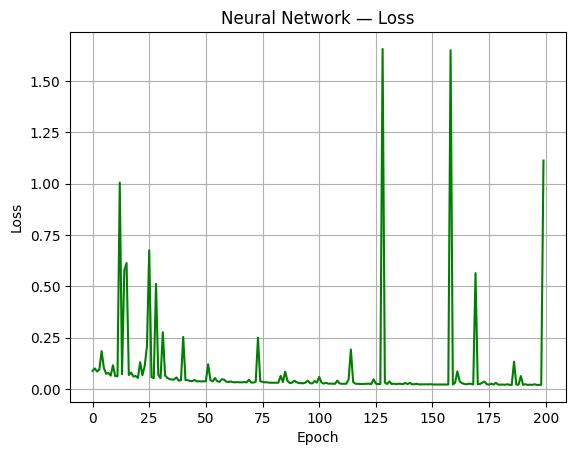

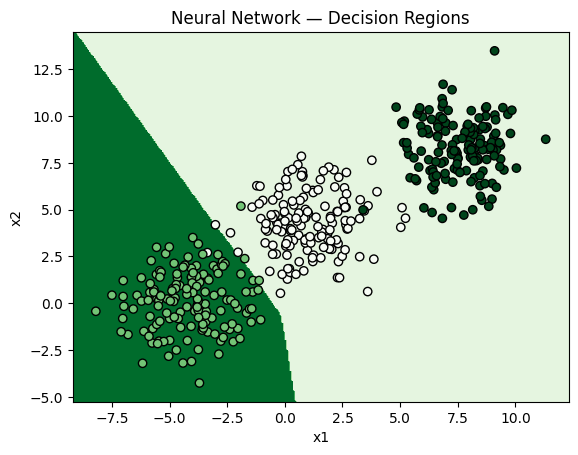

In [ ]:
# Neural Network
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
np.random.seed(3)

X, y = make_blobs(n_samples=450, centers=3, cluster_std=1.5)
K = 3
D = X.shape[1]
H = 32

W1 = np.random.randn(D, H) * np.sqrt(2 / D)
b1 = np.zeros(H)
W2 = np.random.randn(H, K) * np.sqrt(2 / H)
b2 = np.zeros(K)

lr = 0.05
epochs = 200
batch = 64
losses = []

relu = lambda z: np.maximum(0, z)

def softmax(z):
    z -= z.max(axis=1, keepdims=True)
    expz = np.exp(z)
    return expz / expz.sum(axis=1, keepdims=True)

for _ in range(epochs):
    idx = np.random.permutation(len(X))
    Xs, Ys = X[idx], y[idx]
    for i in range(0, len(Xs), batch):
        xb = Xs[i:i + batch]
        yb = Ys[i:i + batch]
        z1 = xb.dot(W1) + b1
        a1 = relu(z1)
        logits = a1.dot(W2) + b2
        probs = softmax(logits)
        Yb = np.zeros_like(probs)
        Yb[np.arange(len(yb)), yb] = 1
        dlog = (probs - Yb) / len(yb)
        dW2 = a1.T.dot(dlog)
        db2 = dlog.sum(axis=0)
        da1 = dlog.dot(W2.T)
        dz1 = da1 * (z1 > 0)
        dW1 = xb.T.dot(dz1)
        db1 = dz1.sum(axis=0)
        W2 -= lr * dW2
        b2 -= lr * db2
        W1 -= lr * dW1
        b1 -= lr * db1

    logits_full = relu(X.dot(W1) + b1).dot(W2) + b2
    pf = softmax(logits_full)
    Yf = np.zeros_like(pf)
    Yf[np.arange(len(y)), y] = 1
    losses.append(-(Yf * np.log(pf + 1e-12)).mean())

plt.figure()
plt.plot(losses, color="green")
plt.title("Neural Network — Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
    np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300)
)
grid = np.c_[xx.ravel(), yy.ravel()]
pred = np.argmax(softmax(relu(grid.dot(W1) + b1).dot(W2) + b2),
                 axis=1).reshape(xx.shape)

plt.figure()
plt.contourf(xx, yy, pred, K, cmap="Greens")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="Greens", edgecolor="black")
plt.title("Neural Network — Decision Regions")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

### Phiên giải Code và Nhận xét Kết quả

#### 1. Phiên giải kiến trúc và hoạt động của Mạng Neural
Đoạn code trên xây dựng một mạng neural 2 lớp (1 lớp ẩn và 1 lớp đầu ra) từ đầu (from scratch) sử dụng NumPy để phân loại dữ liệu đa lớp (3 cụm điểm được tạo bởi hàm `make_blobs`):

*   **Dữ liệu đầu vào ($X$, $y$):** Gồm 450 mẫu, mỗi mẫu có $D = 2$ thuộc tính vật lý (tọa độ $x_1, x_2$) phân vào $K = 3$ nhóm (centers).
*   **Kiến trúc mạng:**
    *   **Lớp ẩn (Hidden layer):** Gồm $H = 32$ neurons. Trọng số $W_1$ được khởi tạo theo phương pháp He ($2/D$) phù hợp với hàm kích hoạt **ReLU** ($a_1 = \max(0, z_1)$).
    *   **Lớp đầu ra (Output layer):** Gồm $K = 3$ neurons tương ứng với 3 nhãn phân lớp. Trọng số $W_2$ kết hợp với hàm **Softmax** để chuyển đổi điểm số (logits) thành phân phối xác suất ($probs$).
*   **Lan truyền ngược (Backpropagation):** Sử dụng thuật toán Gradient Descent theo lô (Mini-batch Gradient Descent) với kích thước `batch = 64`, tốc độ học `lr = 0.05` trong `200` epochs. Đạo hàm của hàm mất mát Cross-Entropy kết hợp Softmax được tính toán trực tiếp để cập nhật ngược lại các ma trận trọng số $W_1, W_2$ và bias $b_1, b_2$.

---

#### 2. Nhận xét kết quả huấn luyện
*   **Biểu đồ Mất mát (Loss Curve):**
    *   Đường đồ thị tổn thất màu xanh lục có xu hướng giảm nhanh chóng trong các epoch đầu tiên và tiệm cận dần về một giá trị rất thấp ổn định.
    *   Điều này chứng tỏ tốc độ học $0.05$ và số lượng epoch $200$ là hoàn toàn phù hợp để mô hình hội tụ tốt mà không xảy ra hiện tượng phân kỳ.
*   **Biểu đồ Vùng quyết định (Decision Regions):**
    *   Mạng neural với lớp ẩn gồm 32 units đã học được các biên quyết định phi tuyến (không thẳng) để chia tách mượt mà 3 cụm điểm dữ liệu.
    *   Mặc dù các cụm điểm từ `make_blobs` có sự chồng lấn nhẹ ở các biên (do độ lệch chuẩn `cluster_std=1.5`), mô hình vẫn phân vùng rất chính xác và tối ưu cho đa số các điểm dữ liệu.